# TP3 Small : prédire le poste d'un joueur de Premier League à partir de ses statistiques

Hugo EXERTIER (ID 06), cours de Big Data 5A, rendu du 18/11/2026. Partie small data du TP3 (dossier `Small/`).

Notebook d'origine (Kaggle) : [English Premier League Players Statistics](https://www.kaggle.com/code/desalegngeb/english-premier-league-players-statistics/notebook) de desalegngeb.
Données : [Premier League player statistics](https://www.kaggle.com/datasets/rishikeshkanabar/premier-league-player-statistics-updated-daily), état au 24/09/2020 (571 joueurs, 59 colonnes).

Question : est-ce qu'on peut deviner si un joueur est défenseur, milieu ou attaquant seulement à partir de ses statistiques ?

## Contribution

### Le notebook est-il correct ?

Oui, ce notebook s'exécute de bout en bout sans erreur (Python 3.12, avec les versions de `requirements-dev.txt`). Pour la partie PySpark, il faut aussi Java 17 ou 21 (sous Windows, il faut passer par WSL ou Docker).

Le notebook d'origine fait seulement une analyse exploratoire avec pandas et des graphiques (nationalités, clubs, meilleurs buteurs...). Il n'y a pas de préparation des données pour le Machine Learning, pas de modèle, pas d'évaluation, pas de déploiement, et il n'utilise pas PySpark.

### Problèmes rencontrés

1. Fuite de données par les valeurs manquantes : le site de la Premier League n'affiche pas les mêmes statistiques selon le poste (`Shots` manque pour 98 % des défenseurs, `Recoveries` pour 96 % des attaquants...). Si on remplace ces vides par 0, le modèle reconnaît le poste grâce aux vides et obtient un score presque parfait qui ne veut rien dire. On a donc gardé seulement les 17 statistiques renseignées pour tous les postes.
2. Les stats sont cumulées sur toute la carrière : un joueur avec 300 matchs a forcément plus de tacles qu'un joueur avec 20 matchs. On les a ramenées par match, et on a enlevé les joueurs avec moins de 10 matchs car leurs stats ne sont pas fiables.
3. Les gardiens se reconnaissent tout de suite (arrêts, clean sheets), donc on les a enlevés, sinon la tâche n'a pas d'intérêt.
4. Les colonnes en pourcentage sont stockées en texte (`"81%"`), il a fallu les convertir en nombres.

### Modifications apportées

- On a ajouté toutes les étapes après l'EDA : prétraitement, transformation, ML (régression logistique, Random Forest, Gradient Boosting, `GridSearchCV`), évaluation (validation croisée, matrice de confusion, importance des variables, analyse des erreurs) et déploiement (sauvegarde du modèle, app Streamlit et Docker).
- En plus, un clustering KMeans avec une ACP, pour voir si on retrouve des profils de joueurs sans utiliser le poste.
- Partie PySpark (section 8) : comme le notebook d'origine n'utilise pas PySpark, on refait la lecture, le prétraitement, la transformation, l'entraînement et l'évaluation avec Spark (DataFrames, Spark SQL, Spark ML), et on compare avec pandas et scikit-learn.
- Le code de préparation est dans `src/features.py`, pour être utilisé à la fois par le notebook et par l'app.

### Autres informations

- Les données (96 Ko) sont dans `data/`. Le modèle et ses métriques sont enregistrés dans `models/` par la partie déploiement.
- Chaque section commence par une cellule `## [Étape]` : Data, EDA, Prétraitement, Transformation, ML, Éval, Déploiement, puis les mêmes étapes pour la partie PySpark.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as F

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## [Data]

## 1. Data

Le dataset Kaggle [`rishikeshkanabar/premier-league-player-statistics-updated-daily`](https://www.kaggle.com/datasets/rishikeshkanabar/premier-league-player-statistics-updated-daily) date du 24/09/2020. Pour chaque joueur de l'effectif 2020-21, les stats sont cumulées sur toute sa carrière en Premier League.

In [2]:
raw = F.load_raw()
print(raw.shape)
raw.head()

(571, 59)


,Name,Jersey Number,Club,Position,Nationality,Age,Appearances,Wins,Losses,Goals,Goals per match,Headed goals,Goals with right foot,Goals with left foot,Penalties scored,Freekicks scored,Shots,Shots on target,Shooting accuracy %,Hit woodwork,Big chances missed,Clean sheets,Goals conceded,Tackles,Tackle success %,Last man tackles,Blocked shots,Interceptions,Clearances,Headed Clearance,Clearances off line,Recoveries,Duels won,Duels lost,Successful 50/50s,Aerial battles won,Aerial battles lost,Own goals,Errors leading to goal,Assists,Passes,Passes per match,Big chances created,Crosses,Cross accuracy %,Through balls,Accurate long balls,Saves,Penalties saved,Punches,High Claims,Catches,Sweeper clearances,Throw outs,Goal Kicks,Yellow cards,Red cards,Fouls,Offsides
0,Bernd Leno,1.0,Arsenal,Goalkeeper,Germany,28.0,64,28,16,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,82.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,7.0,0,1783,27.86,NaN,NaN,NaN,NaN,234.0,222.0,1.0,34.0,26.0,17.0,28.0,375.0,489.0,2,0,0,NaN
1,Matt Macey,33.0,Arsenal,Goalkeeper,England,26.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0,0,0.00,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
2,Rúnar Alex Rúnarsson,13.0,Arsenal,Goalkeeper,Iceland,25.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0,0,0.00,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
3,Héctor Bellerín,2.0,Arsenal,Defender,Spain,25.0,160,90,37,7,NaN,0.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,3.0,NaN,53.0,166.0,214.0,78%,1.0,32.0,208.0,304.0,143.0,3.0,732.0,611.0,709.0,196.0,161.0,215.0,1.0,1.0,18,7125,44.53,28.0,389.0,16%,31.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,0,125,8.0
4,Kieran Tierney,3.0,Arsenal,Defender,Scotland,23.0,16,7,5,1,NaN,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,2.0,16.0,21.0,81%,0.0,1.0,12.0,32.0,12.0,0.0,63.0,55.0,38.0,12.0,10.0,16.0,0.0,0.0,1,519,32.44,1.0,45.0,18%,0.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,9,0.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 571 entries, 0 to 570
Data columns (total 59 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Name                    571 non-null    str    
 1   Jersey Number           563 non-null    float64
 2   Club                    571 non-null    str    
 3   Position                571 non-null    str    
 4   Nationality             570 non-null    str    
 5   Age                     570 non-null    float64
 6   Appearances             571 non-null    int64  
 7   Wins                    571 non-null    int64  
 8   Losses                  571 non-null    int64  
 9   Goals                   571 non-null    int64  
 10  Goals per match         309 non-null    float64
 11  Headed goals            502 non-null    float64
 12  Goals with right foot   502 non-null    float64
 13  Goals with left foot    502 non-null    float64
 14  Penalties scored        309 non-null    float64
 15  

## [EDA]

## 2. EDA

L'EDA complète (nationalités, clubs, meilleurs buteurs...) est déjà faite dans le notebook d'origine. Ici on regarde surtout ce qui sert pour la question : est-ce que les postes se distinguent par leurs stats ?

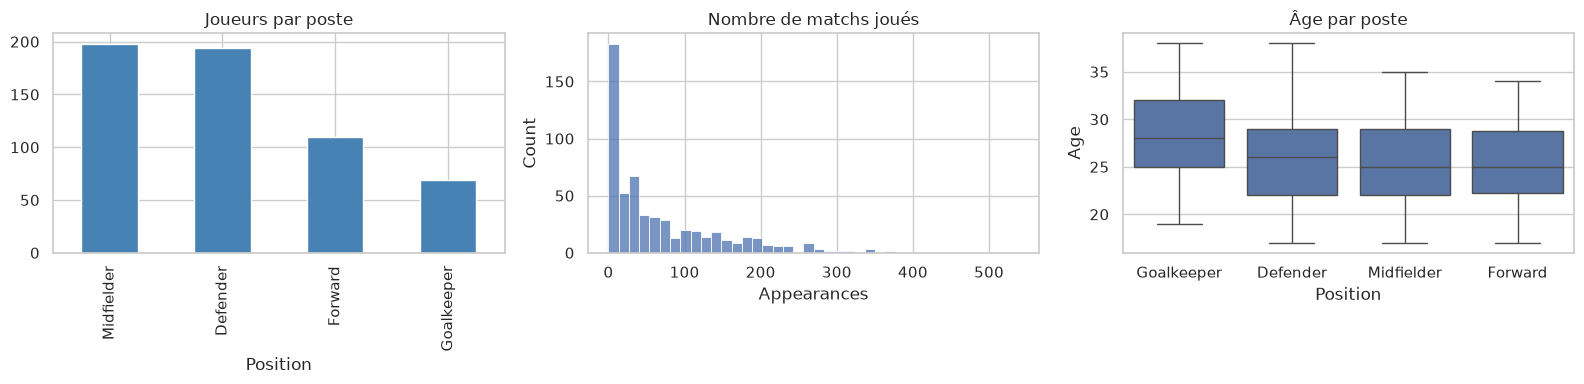

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw["Position"].value_counts().plot.bar(ax=axes[0], color="steelblue", title="Joueurs par poste")
sns.histplot(raw["Appearances"], bins=40, ax=axes[1]).set_title("Nombre de matchs joués")
sns.boxplot(data=raw, x="Position", y="Age", ax=axes[2]).set_title("Âge par poste")
plt.tight_layout(); plt.show()

Il y a à peu près autant de défenseurs (194) que de milieux (198), et moins d'attaquants (110).

Le nombre de matchs joués est très déséquilibré : beaucoup de joueurs n'ont presque pas joué, donc leurs stats ne sont pas fiables et il faudra les enlever.

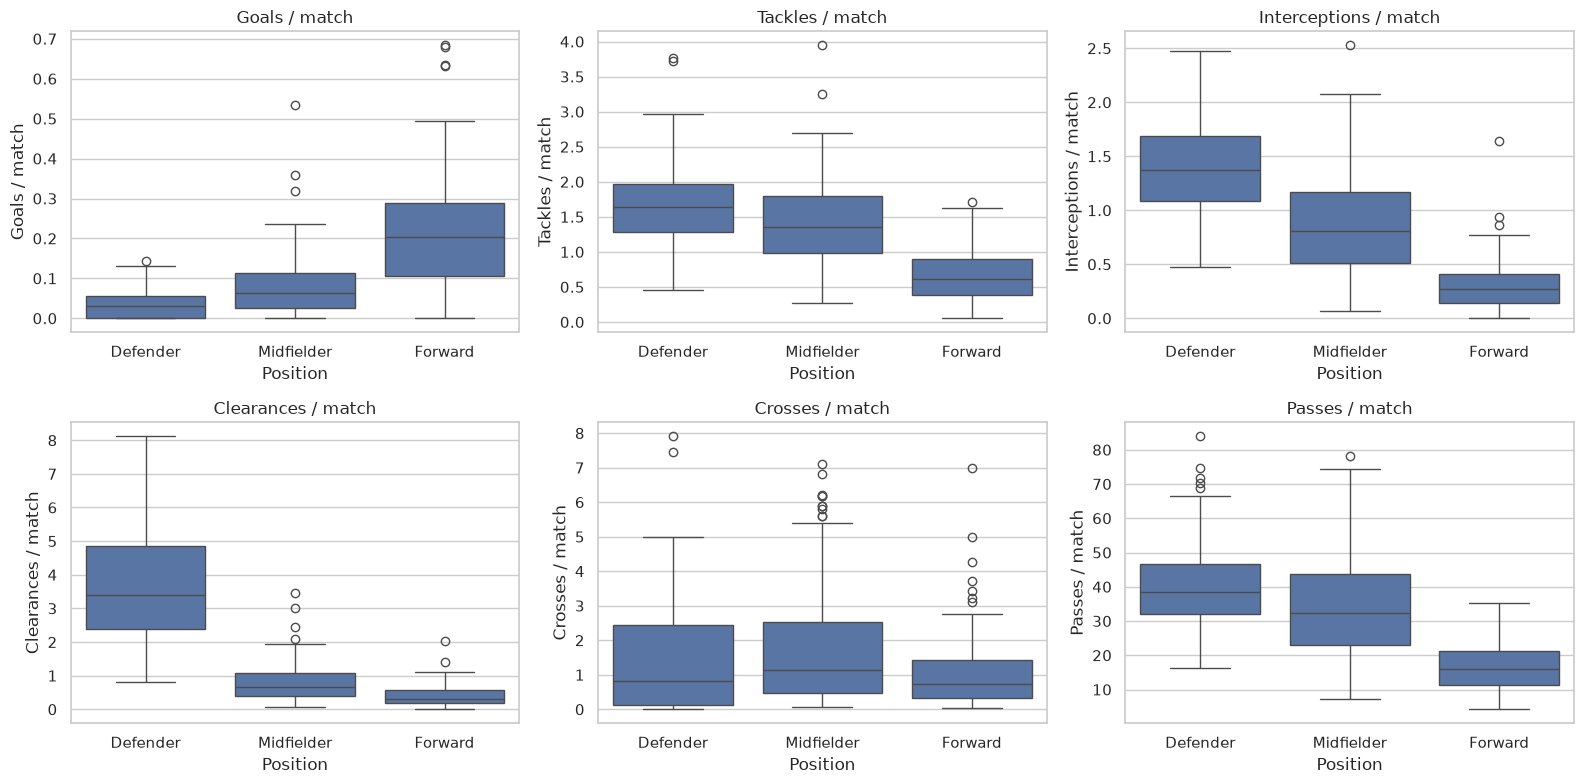

In [5]:
tmp = raw[raw["Appearances"] >= 10].copy()
for c in ["Goals", "Tackles", "Interceptions", "Clearances", "Crosses", "Passes"]:
    tmp[c + " / match"] = tmp[c] / tmp["Appearances"]
cols = ["Goals / match", "Tackles / match", "Interceptions / match", "Clearances / match", "Crosses / match", "Passes / match"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, cols):
    sns.boxplot(data=tmp[tmp.Position != "Goalkeeper"], x="Position", y=c, ax=ax, order=F.POSITIONS)
    ax.set_title(c)
plt.tight_layout(); plt.show()

Chaque poste a des stats bien différentes : les attaquants marquent plus, les défenseurs font plus de dégagements et les milieux plus de passes. Les milieux sont entre les deux, donc on s'attend à ce que ce soit le poste où le modèle se trompe le plus.

## [Prétraitement]

## 3. Prétraitement

### 3.1 Le problème des valeurs manquantes

On regarde le taux de valeurs manquantes pour chaque poste :

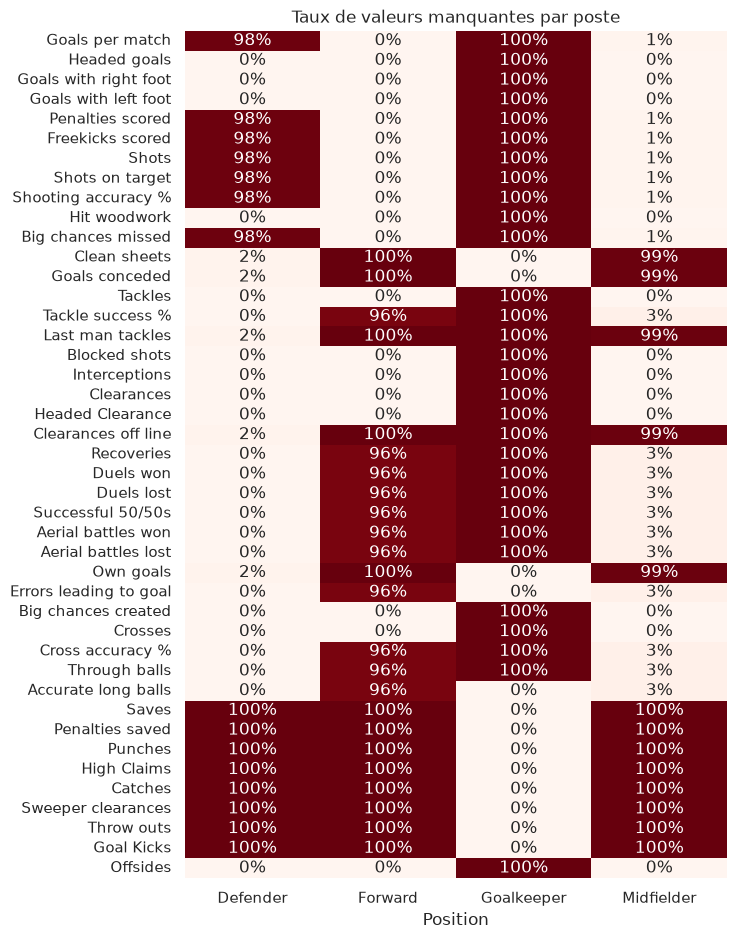

In [6]:
na_by_pos = raw.drop(columns=["Name", "Club", "Nationality"]).isna().groupby(raw["Position"]).mean().T
na_by_pos = na_by_pos[(na_by_pos > 0.05).any(axis=1)]
plt.figure(figsize=(7, 11))
sns.heatmap(na_by_pos, cmap="Reds", annot=True, fmt=".0%", cbar=False)
plt.title("Taux de valeurs manquantes par poste"); plt.show()

Le site de la Premier League n'affiche pas les mêmes stats selon le poste : `Shots` manque pour 98 % des défenseurs, `Recoveries` ou `Duels won` pour 96 % des attaquants, etc.

Si on remplaçait ces vides par 0, le modèle apprendrait par exemple « pas de tirs renseignés = défenseur ». Il aurait un score presque parfait, mais seulement parce qu'il triche avec les valeurs manquantes (fuite de données).

On garde donc seulement les 17 statistiques renseignées pour tous les joueurs de champ (liste `F.COUNT_STATS`).

In [7]:
print(len(F.COUNT_STATS), "stats retenues :", F.COUNT_STATS)

17 stats retenues : ['Goals', 'Headed goals', 'Goals with right foot', 'Goals with left foot', 'Hit woodwork', 'Assists', 'Big chances created', 'Passes', 'Crosses', 'Tackles', 'Blocked shots', 'Interceptions', 'Clearances', 'Headed Clearance', 'Fouls', 'Offsides', 'Yellow cards']


### 3.2 Nettoyage

- on convertit les colonnes en `%` (du texte comme `"81%"`) en nombres ;
- on supprime les lignes sans âge ou sans nationalité ;
- on enlève les gardiens : leurs stats (arrêts, clean sheets) les trahissent tout de suite, la tâche serait trop facile ;
- on enlève les joueurs avec moins de 10 matchs, car leurs stats ne sont pas fiables ;
- les vides qui restent dans les 17 stats sont remplacés par 0 (moins de 1 % des cas, ça correspond à « aucune action »).

In [8]:
df = F.clean(raw)
print(f"{len(raw)} joueurs -> {len(df)} après nettoyage")
df["Position"].value_counts()

571 joueurs -> 366 après nettoyage


Position
Midfielder    146
Defender      129
Forward        91
Name: count, dtype: int64

## [Transformation]

## 4. Transformation

Les stats sont cumulées sur toute la carrière : un joueur avec 300 matchs a forcément plus de tacles qu'un joueur avec 20 matchs. On divise donc par le nombre de matchs, pour comparer des façons de jouer et pas des carrières.

In [9]:
df = F.add_per_match(df)
X = df[F.FEATURES]
y = df["Position"]
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Goals / match,366.0,0.098,0.114,0.000,0.024,0.060,0.132,0.684
Headed goals / match,366.0,0.016,0.027,0.000,0.000,0.000,0.023,0.139
Goals with right foot / match,366.0,0.053,0.077,0.000,0.000,0.024,0.071,0.533
Goals with left foot / match,366.0,0.028,0.051,0.000,0.000,0.008,0.035,0.512
Hit woodwork / match,366.0,0.025,0.029,0.000,0.000,0.017,0.038,0.200
Assists / match,366.0,0.075,0.066,0.000,0.028,0.062,0.104,0.467
Big chances created / match,366.0,0.107,0.090,0.000,0.041,0.083,0.158,0.622
Passes / match,366.0,32.160,15.524,4.226,20.640,31.214,41.977,84.017
Crosses / match,366.0,1.512,1.596,0.000,0.299,0.907,2.340,7.917
Tackles / match,366.0,1.327,0.665,0.053,0.810,1.290,1.731,3.951


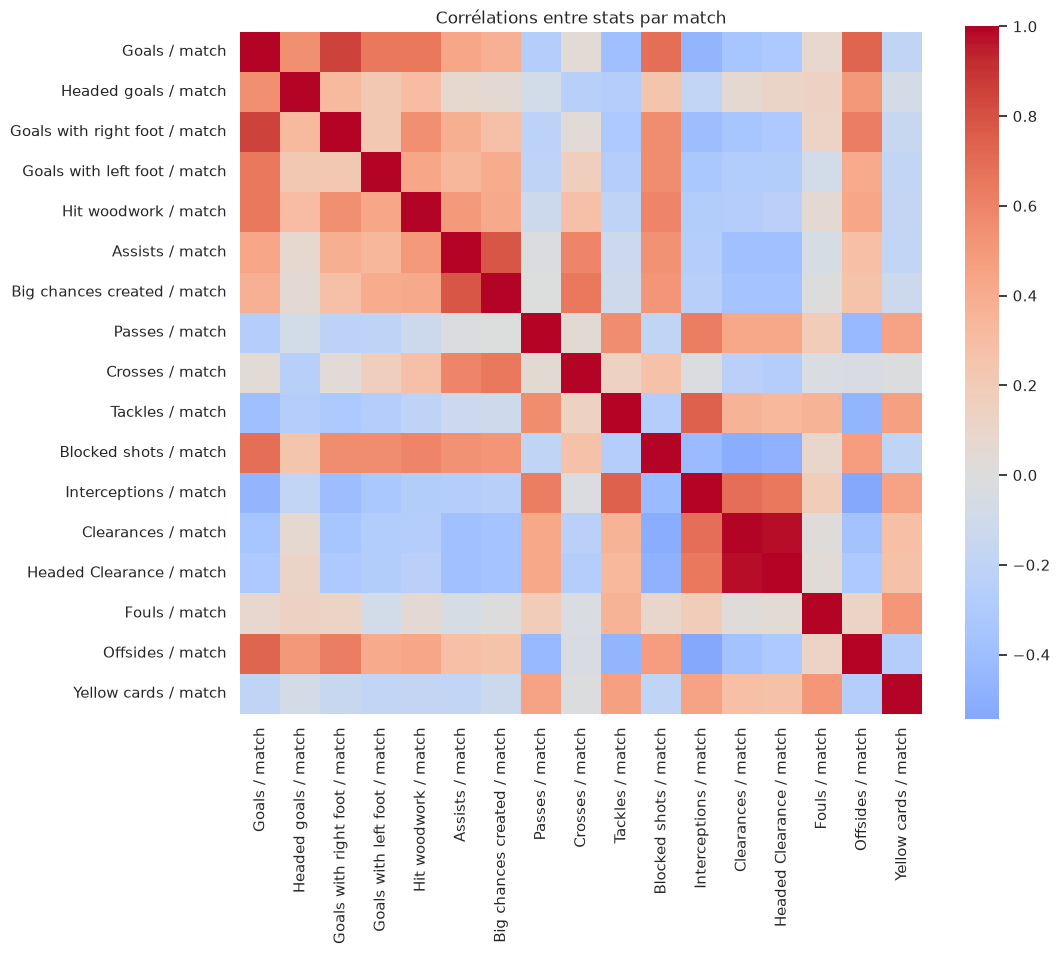

In [10]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, square=True)
plt.title("Corrélations entre stats par match"); plt.show()

Les valeurs n'ont pas du tout la même échelle (environ 30 passes par match contre 0,05 but de la tête par match), donc on les standardise avec `StandardScaler`. On le met dans un `Pipeline` scikit-learn : comme ça, il est calculé seulement sur les données d'entraînement (pas de fuite) et il est réappliqué automatiquement au moment de prédire.

## [ML]

## 5. Machine Learning

### 5.1 Classification du poste

On découpe les données en 80 % pour l'entraînement et 20 % pour le test, en gardant la même proportion de chaque poste. Le test ne sert qu'à la fin.

On compare trois modèles par validation croisée à 5 plis sur les données d'entraînement : avec si peu de joueurs, un seul découpage donnerait un résultat trop dépendant du hasard.

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

models = {
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"modèle": name,
                 "accuracy": s["test_accuracy"].mean(), "accuracy ±": s["test_accuracy"].std(),
                 "F1 macro": s["test_f1_macro"].mean(), "F1 macro ±": s["test_f1_macro"].std()})
cv_results = pd.DataFrame(rows).set_index("modèle").round(3)
cv_results

,accuracy,accuracy ±,F1 macro,F1 macro ±
modèle,,,,
Régression logistique,0.867,0.038,0.866,0.036
Random Forest,0.870,0.030,0.869,0.026
Gradient Boosting,0.846,0.022,0.845,0.018


### 5.2 Optimisation des hyperparamètres

On cherche les meilleurs réglages avec `GridSearchCV` (même validation croisée) pour la régression logistique (paramètre de régularisation `C`) et pour le Random Forest.

In [12]:
grids = {
    "Régression logistique": (LogisticRegression(max_iter=2000), {"model__C": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
                      {"model__n_estimators": [200, 500], "model__max_depth": [None, 6, 10],
                       "model__min_samples_leaf": [1, 3]}),
}
searches = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", model)]),
                      grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:22s} F1 CV = {gs.best_score_:.3f}  {gs.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = searches[best_name].best_estimator_
print("\nModèle retenu :", best_name)

Régression logistique  F1 CV = 0.870  {'model__C': 10}


Random Forest          F1 CV = 0.872  {'model__max_depth': 6, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Modèle retenu : Random Forest


## [Éval]

## 6. Évaluation

### 6.1 Sur le jeu de test

{'accuracy': 0.8513513513513513, 'f1_macro': 0.8516554162648666}
              precision    recall  f1-score   support

    Defender      0.920     0.885     0.902        26
     Forward      0.833     0.833     0.833        18
  Midfielder      0.806     0.833     0.820        30

    accuracy                          0.851        74
   macro avg      0.853     0.850     0.852        74
weighted avg      0.853     0.851     0.852        74



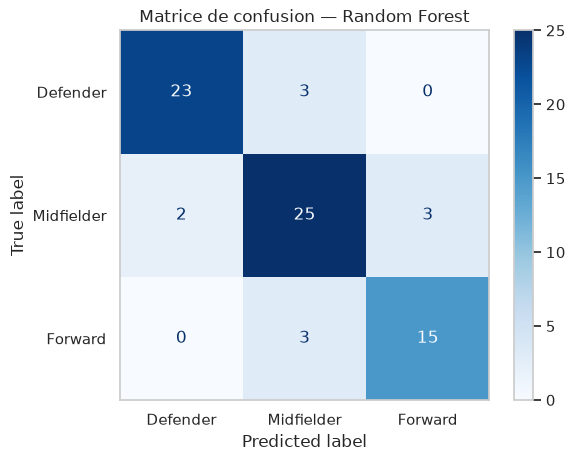

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

y_pred = best_model.predict(X_test)
test_metrics = {"accuracy": accuracy_score(y_test, y_pred), "f1_macro": f1_score(y_test, y_pred, average="macro")}
print(test_metrics)
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=F.POSITIONS, cmap="Blues")
plt.title(f"Matrice de confusion — {best_name}"); plt.grid(False); plt.show()

Comme prévu, la plupart des erreurs concernent les milieux : un milieu défensif ressemble à un défenseur, et un milieu offensif à un attaquant. Un modèle qui répondrait au hasard aurait environ 33 %, donc le modèle a bien appris quelque chose.

### 6.2 Quelles stats comptent le plus ? (importance par permutation)

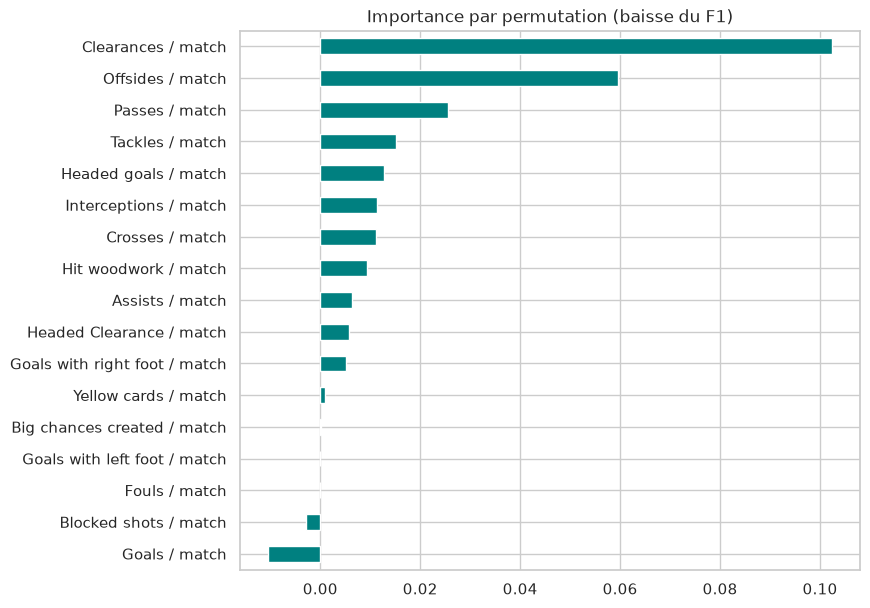

In [14]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                            n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(imp.importances_mean, index=F.FEATURES).sort_values()
imp.plot.barh(figsize=(8, 7), color="teal", title="Importance par permutation (baisse du F1)")
plt.show()

### 6.3 Les erreurs intéressantes

On regarde, sur tous les joueurs (prédictions faites en validation croisée), lesquels ont des stats qui ne correspondent pas à leur poste officiel.

In [15]:
from sklearn.model_selection import cross_val_predict
df["Poste prédit"] = cross_val_predict(best_model, X, y, cv=cv)
errors = df[df["Poste prédit"] != df["Position"]][["Name", "Club", "Position", "Poste prédit", "Appearances"]]
print(f"{len(errors)} joueurs « mal classés » sur {len(df)}")
errors.sort_values("Appearances", ascending=False).head(15)

47 joueurs « mal classés » sur 366


,Name,Club,Position,Poste prédit,Appearances
69,Jack Cork,Burnley,Midfielder,Defender,264
23,Willian,Arsenal,Forward,Midfielder,236
288,Ryan Bertrand,Southampton,Defender,Midfielder,231
215,Fernandinho,Manchester-City,Midfielder,Defender,225
114,Wilfried Zaha,Crystal-Palace,Forward,Midfielder,217
240,Nemanja Matic,Manchester-United,Midfielder,Defender,208
220,Riyad Mahrez,Manchester-City,Forward,Midfielder,199
107,Cheikhou Kouyaté,Crystal-Palace,Midfielder,Defender,197
311,Eric Dier,Tottenham-Hotspur,Midfielder,Defender,176
322,Gareth Bale,Tottenham-Hotspur,Forward,Midfielder,146


La plupart de ces erreurs s'expliquent : des latéraux très offensifs sont prédits milieux, des milieux offensifs sont prédits attaquants... Le poste officiel ne dit pas tout, alors que le modèle voit la façon de jouer.

### 6.4 Bonus : clustering sans utiliser le poste

On ne donne plus le poste et on laisse KMeans regrouper les joueurs. On choisit `k` avec le score de silhouette, et on affiche les groupes en 2D avec une ACP.

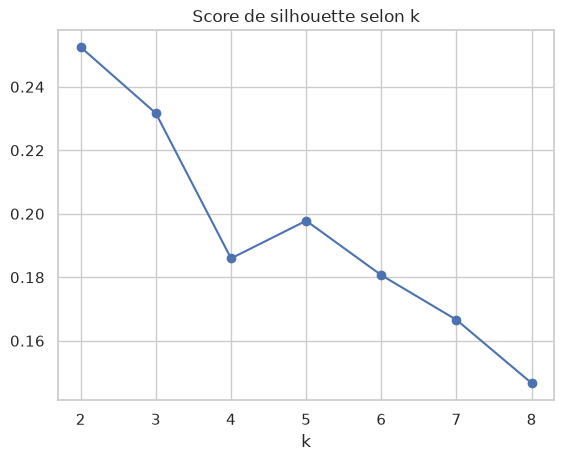

In [16]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

X_scaled = StandardScaler().fit_transform(X)
sil = {k: silhouette_score(X_scaled, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled))
       for k in range(2, 9)}
pd.Series(sil).plot(marker="o", title="Score de silhouette selon k"); plt.xlabel("k"); plt.show()

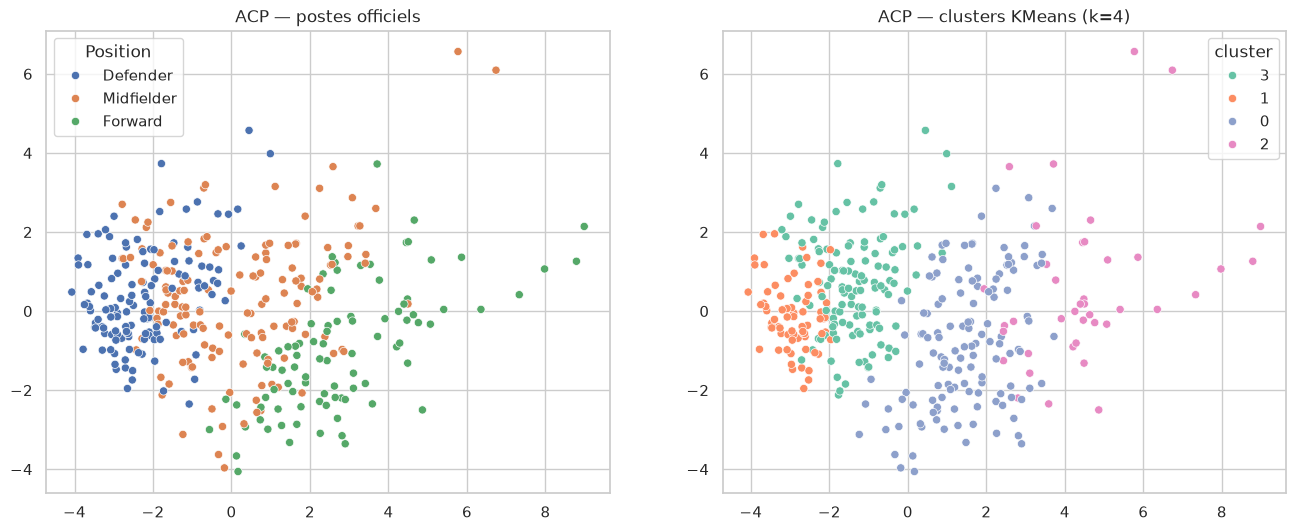

Position,Defender,Forward,Midfielder
cluster,,,
0,3,56,71
1,69,0,2
2,0,35,5
3,57,0,68


In [17]:
K = 4  # compromis lisibilité / silhouette : un groupe de plus que les 3 postes
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
df["cluster"] = km.labels_
coords = PCA(2, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["Position"], ax=axes[0], s=35).set_title("ACP — postes officiels")
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["cluster"].astype(str), palette="Set2", ax=axes[1], s=35).set_title(f"ACP — clusters KMeans (k={K})")
plt.show()
pd.crosstab(df["cluster"], df["Position"])

In [18]:
# Profil moyen de chaque cluster (z-scores) pour les nommer
profile = pd.DataFrame(km.cluster_centers_, columns=F.FEATURES).T.round(2)
profile.style.background_gradient(cmap="RdBu_r", axis=None)

,0,1,2,3
Goals / match,0.100000,-0.500000,2.220000,-0.530000
Headed goals / match,-0.260000,0.260000,1.740000,-0.440000
Goals with right foot / match,0.110000,-0.530000,1.870000,-0.410000
Goals with left foot / match,0.190000,-0.460000,1.210000,-0.320000
Hit woodwork / match,0.120000,-0.450000,1.570000,-0.370000
Assists / match,0.270000,-0.790000,1.010000,-0.160000
Big chances created / match,0.290000,-0.730000,0.820000,-0.150000
Passes / match,-0.740000,0.780000,-0.500000,0.490000
Crosses / match,0.250000,-0.730000,-0.100000,0.180000
Tackles / match,-0.680000,0.240000,-0.780000,0.820000


Les groupes retrouvent à peu près les postes, mais on voit aussi des profils plus précis : par exemple les défenseurs centraux qui font beaucoup de dégagements et les latéraux qui centrent beaucoup, ou les milieux récupérateurs et les milieux créateurs.

Dans le tableau, une valeur positive veut dire que le groupe est au-dessus de la moyenne pour cette stat.

## [Déploiement]

## 7. Déploiement

On réentraîne le meilleur modèle sur toutes les données, puis on le sauvegarde avec `joblib`, avec un fichier de métadonnées. L'app Streamlit `app/streamlit_app.py` recharge ce modèle et applique les mêmes transformations grâce à `src/features.py`.

```bash
streamlit run app/streamlit_app.py
```

In [19]:
import joblib, sklearn

final_model = best_model.fit(X, y)
models_dir = ROOT / "models"
models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / "position_model.joblib")

metadata = {
    "model": best_name,
    "params": searches[best_name].best_params_,
    "features": F.FEATURES,
    "classes": list(final_model.classes_),
    "cv_f1_macro": round(searches[best_name].best_score_, 4),
    "test_accuracy": round(test_metrics["accuracy"], 4),
    "test_f1_macro": round(test_metrics["f1_macro"], 4),
    "n_train_rows": len(X),
    "sklearn_version": sklearn.__version__,
}
(models_dir / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
metadata

{'model': 'Random Forest',
 'params': {'model__max_depth': 6,
  'model__min_samples_leaf': 1,
  'model__n_estimators': 200},
 'features': ['Goals / match',
  'Headed goals / match',
  'Goals with right foot / match',
  'Goals with left foot / match',
  'Hit woodwork / match',
  'Assists / match',
  'Big chances created / match',
  'Passes / match',
  'Crosses / match',
  'Tackles / match',
  'Blocked shots / match',
  'Interceptions / match',
  'Clearances / match',
  'Headed Clearance / match',
  'Fouls / match',
  'Offsides / match',
  'Yellow cards / match'],
 'classes': ['Defender', 'Forward', 'Midfielder'],
 'cv_f1_macro': np.float64(0.8722),
 'test_accuracy': 0.8514,
 'test_f1_macro': 0.8517,
 'n_train_rows': 366,
 'sklearn_version': '1.9.1'}

## [Data]

## 8. Même traitement avec PySpark

Le notebook d'origine n'utilise pas PySpark, donc on refait le traitement avec Spark, étape par étape, et on compare avec la version pandas / scikit-learn.

Spark tourne en local (`local[*]` : il utilise tous les cœurs du processeur). Il faut Java 17 ou 21 (sous Windows, passer par WSL ou Docker).

### 8.1 Lecture du CSV avec Spark

Avec `inferSchema`, Spark devine le type de chaque colonne. On importe les fonctions Spark sous le nom `SF`, parce que `F` est déjà utilisé pour notre module `src/features.py`.

In [20]:
from pyspark.sql import SparkSession, functions as SF
import os

# Les workers Spark doivent utiliser le même Python que le notebook
os.environ["PYSPARK_PYTHON"] = sys.executable

spark = (SparkSession.builder.master("local[*]").appName("epl-small")
         .config("spark.sql.shuffle.partitions", "4")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| parallélisme :", spark.sparkContext.defaultParallelism)

sdf_raw = spark.read.csv(str(F.DATA_PATH), header=True, inferSchema=True)
print(sdf_raw.count(), "lignes,", len(sdf_raw.columns), "colonnes")
sdf_raw.select("Name", "Club", "Position", "Age", "Appearances", "Goals", "Passes", "Shooting accuracy %").show(5)

Spark 4.0.1 | parallélisme : 20


571 lignes, 59 colonnes


+--------------------+-------+----------+---+-----------+-----+------+-------------------+
|                Name|   Club|  Position|Age|Appearances|Goals|Passes|Shooting accuracy %|
+--------------------+-------+----------+---+-----------+-----+------+-------------------+
|          Bernd Leno|Arsenal|Goalkeeper| 28|         64|    0|  1783|               NULL|
|          Matt Macey|Arsenal|Goalkeeper| 26|          0|    0|     0|               NULL|
|Rúnar Alex Rúnarsson|Arsenal|Goalkeeper| 25|          0|    0|     0|               NULL|
|     Héctor Bellerín|Arsenal|  Defender| 25|        160|    7|  7125|               NULL|
|      Kieran Tierney|Arsenal|  Defender| 23|         16|    1|   519|               NULL|
+--------------------+-------+----------+---+-----------+-----+------+-------------------+
only showing top 5 rows


## [Prétraitement]

### 8.2 Prétraitement avec Spark

On applique les mêmes règles que `F.clean` : pourcentages convertis en nombres, lignes sans âge ou sans nationalité supprimées, gardiens enlevés, au moins 10 matchs, et vides remplacés par 0 dans les 17 stats gardées.

In [21]:
sdf = sdf_raw
for c in [c for c in sdf_raw.columns if c.endswith("%")]:
    sdf = sdf.withColumn(c, SF.regexp_replace(SF.col(c).cast("string"), "%", "").cast("double"))

sdf = (sdf.dropna(subset=["Age", "Nationality"])
          .filter(SF.col("Position").isin(F.POSITIONS))
          .filter(SF.col("Appearances") >= F.MIN_APPEARANCES)
          .fillna(0, subset=F.COUNT_STATS))

print(sdf_raw.count(), "joueurs ->", sdf.count(), "après nettoyage (pandas :", len(df), ")")
sdf.groupBy("Position").count().orderBy("Position").show()

571 joueurs -> 366 après nettoyage (pandas : 366 )


+----------+-----+
|  Position|count|
+----------+-----+
|  Defender|  129|
|   Forward|   91|
|Midfielder|  146|
+----------+-----+



## [Transformation]

### 8.3 Transformation avec Spark : stats par match

On divise les 17 stats par le nombre de matchs, comme dans `F.add_per_match`, puis on vérifie que Spark et pandas donnent les mêmes valeurs.

In [22]:
sdf_feat = sdf.select("Name", "Club", "Position", "Appearances",
                     *[(SF.col(c) / SF.col("Appearances")).alias(f"{c} / match") for c in F.COUNT_STATS]).cache()

spark_pd = sdf_feat.select("Name", "Club", *F.FEATURES).toPandas().sort_values(["Name", "Club"]).reset_index(drop=True)
pandas_pd = df[["Name", "Club", *F.FEATURES]].sort_values(["Name", "Club"]).reset_index(drop=True)
print("Mêmes joueurs :", spark_pd[["Name", "Club"]].equals(pandas_pd[["Name", "Club"]]))
print("Mêmes features :", np.allclose(spark_pd[F.FEATURES], pandas_pd[F.FEATURES]))

Mêmes joueurs : True
Mêmes features : True


On retrouve bien les mêmes 366 joueurs et les mêmes 17 valeurs qu'avec pandas : le prétraitement et la transformation donnent le même résultat.

Avec Spark SQL, on retrouve les différences entre postes vues dans l'EDA (les noms de colonnes qui contiennent des espaces doivent être entre accents graves) :

In [23]:
sdf_feat.createOrReplaceTempView("joueurs")
spark.sql('''
    SELECT Position, COUNT(*) AS joueurs,
           ROUND(AVG(`Goals / match`), 3)      AS buts,
           ROUND(AVG(`Passes / match`), 1)     AS passes,
           ROUND(AVG(`Tackles / match`), 2)    AS tacles,
           ROUND(AVG(`Clearances / match`), 2) AS degagements
    FROM joueurs GROUP BY Position ORDER BY Position
''').show()

+----------+-------+-----+------+------+-----------+
|  Position|joueurs| buts|passes|tacles|degagements|
+----------+-------+-----+------+------+-----------+
|  Defender|    129|0.035|  41.0|  1.67|       3.64|
|   Forward|     91|0.216|  16.8|  0.69|       0.42|
|Midfielder|    146| 0.08|  33.9|  1.42|       0.79|
+----------+-------+-----+------+------+-----------+



## [ML]

### 8.4 Machine Learning avec Spark ML

Pour que la comparaison soit juste, on garde les mêmes joueurs de test que pour scikit-learn (jointure sur le nom et le club).

Le pipeline Spark ML enchaîne `StringIndexer` (le poste devient un numéro de classe), `VectorAssembler` (les 17 stats sont regroupées dans un vecteur), `StandardScaler`, puis le modèle. On entraîne une régression logistique et un Random Forest avec les réglages trouvés par `GridSearchCV` (200 arbres, profondeur 6).

In [24]:
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler as SparkScaler, IndexToString
from pyspark.ml.classification import LogisticRegression as SparkLR, RandomForestClassifier as SparkRF
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

test_keys = spark.createDataFrame(df.loc[X_test.index, ["Name", "Club"]]).withColumn("is_test", SF.lit(True))
sdf_ml = sdf_feat.join(test_keys, ["Name", "Club"], "left").fillna(False, subset=["is_test"])
train_s, test_s = sdf_ml.filter(~SF.col("is_test")), sdf_ml.filter(SF.col("is_test"))
print("train :", train_s.count(), "| test :", test_s.count(), "(scikit-learn :", len(X_train), "/", len(X_test), ")")

indexer = StringIndexer(inputCol="Position", outputCol="label").fit(sdf_feat)
prep = [indexer,
        VectorAssembler(inputCols=F.FEATURES, outputCol="raw_features"),
        SparkScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)]
back = IndexToString(inputCol="prediction", outputCol="Poste prédit", labels=indexer.labels)

spark_models = {
    "Régression logistique": SparkLR(maxIter=200),
    "Random Forest": SparkRF(numTrees=200, maxDepth=6, seed=RANDOM_STATE),
}
spark_preds = {}
for name, model in spark_models.items():
    fitted = SparkPipeline(stages=prep + [model, back]).fit(train_s)
    spark_preds[name] = fitted.transform(test_s).cache()

train : 292 | test : 74 (scikit-learn : 292 / 74 )


## [Éval]

### 8.5 Évaluation et comparaison avec scikit-learn

Spark ML ne calcule pas directement le F1 macro (sa métrique `f1` est pondérée par le nombre de joueurs de chaque classe), donc on fait nous-mêmes la moyenne des F1 de chaque classe avec `fMeasureByLabel`.

In [25]:
def spark_scores(pred):
    ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
    acc = ev.evaluate(pred, {ev.metricName: "accuracy"})
    f1s = [ev.evaluate(pred, {ev.metricName: "fMeasureByLabel", ev.metricLabel: float(i)})
           for i in range(len(indexer.labels))]
    return acc, sum(f1s) / len(f1s)

rows = [{"outil": "scikit-learn", "modèle": f"{best_name} (GridSearchCV)",
         "accuracy": test_metrics["accuracy"], "F1 macro": test_metrics["f1_macro"]}]
for name, pred in spark_preds.items():
    acc, f1m = spark_scores(pred)
    rows.append({"outil": "Spark ML", "modèle": name, "accuracy": acc, "F1 macro": f1m})
pd.DataFrame(rows).set_index(["outil", "modèle"]).round(3)

accuracy  F1 macro
outil        modèle                                          
scikit-learn Random Forest (GridSearchCV)     0.851     0.852
Spark ML     Régression logistique            0.865     0.864
             Random Forest                    0.838     0.836

In [26]:
# Matrice de confusion du Random Forest Spark, calculée par Spark
(spark_preds["Random Forest"].groupBy("Position").pivot("Poste prédit", F.POSITIONS).count()
    .fillna(0).orderBy("Position").toPandas().set_index("Position").loc[F.POSITIONS])

,Defender,Midfielder,Forward
Position,,,
Defender,23,3,0
Midfielder,2,25,3
Forward,0,4,14


Sur les mêmes 74 joueurs de test, Spark donne des scores proches de scikit-learn :
- régression logistique Spark : F1 macro de 0,864 ;
- Random Forest Spark : F1 macro de 0,836 ;
- Random Forest scikit-learn (réglé avec `GridSearchCV`) : F1 macro de 0,852.

Les petites différences viennent de la façon dont chaque bibliothèque construit les arbres (Spark limite par exemple le nombre de seuils testés pour chaque variable avec `maxBins`). Avec seulement 74 joueurs de test, un joueur mal classé change l'accuracy de 1,4 point, donc ces écarts ne sont pas vraiment significatifs.

Comme avec scikit-learn, les erreurs concernent les milieux : sur les 12 erreurs du Random Forest Spark, 5 sont des milieux mal classés et 7 sont des défenseurs ou des attaquants prédits milieux. Aucun défenseur n'est pris pour un attaquant.

Avec Spark, il a fallu plus de code (pipeline, F1 macro calculé à la main) et attendre quelques secondes que Spark démarre, pour un fichier de 96 Ko. Sur un aussi petit dataset, Spark n'apporte rien par rapport à pandas et scikit-learn. Il devient utile quand les données ne tiennent plus en mémoire, comme dans la partie Big.

In [27]:
spark.stop()

## [Conclusion]

## Conclusion

- Avec 17 stats ramenées par match, on retrouve le poste d'un joueur de champ dans environ 85 % des cas (F1 de 0,85 sur le test et de 0,87 en validation croisée), contre 33 % au hasard.
- Le prétraitement a été l'étape la plus importante : si on n'avait pas vu que les valeurs manquantes donnaient le poste, on aurait eu un score parfait mais faux.
- Le poste le plus difficile à prédire est milieu de terrain, qui est entre les deux autres. Le clustering montre aussi qu'il regroupe plusieurs profils différents.
- Refaire le traitement avec PySpark donne exactement les mêmes données et des scores du même niveau (F1 macro entre 0,84 et 0,86 sur le test).
- Avec environ 400 joueurs et 17 colonnes, les données ne font que quelques Ko : pandas et scikit-learn suffisent, et la section 8 montre que Spark ajoute surtout du code et du temps de démarrage. C'est l'inverse de la partie Big.